# Project: Transfer Learning 
### Soren Patel

**AI Usage:** I used AI as an assistant for parts of this project. It drafted the markdown formatting and the helper functions for training, evaluation and plotting, and it advised on which plots were relevant to produce. It also suggested and implemented GELU as an activation to compare, t-SNE for visualizing backbone features, ResNet34 and ResNet50 for depth comparison, a set of data augmentations, fine-tuning beyond the head (8C), and training on varying percentages of the training data. I also used it to fix the image RGBA warning. I reviewed and ran all of this code myself.

Pretrained **ResNet18** with a frozen feature extractor and a new trainable head, trained on images scraped from Bing.

**Expected layout** (current directory):
- `train/{boats,cars,planes,trains}/...`
- `test/{boats,cars,planes,trains}/...`

**Sections**
1. Setup
2. Data exploration
3. Transforms and dataset builder
4. Model (ResNet18 + new head)
5. Helper functions (train, evaluate, plot)
6. Baseline (the given code, 20 epochs) + confusion matrix, mistakes, feature embeddings
7. Q1: more classes; which classes are hard?
8. Q2: depth, width, dropout, activations, fine-tuning
9. Q3: learning rate
10. Q4: augmentation, overfitting, normalization
11. Q5: early stopping
12. Extra: how much data do we need?
13. Final model

Experiments use `EXP_EPOCHS` (default 10) to keep runtimes manageable.

## 1. Setup

Setup and imports. Bypasses ITSD MITM attack protection. Checks/confirms GPU or CPU for running time and power. Seeds all random for reproducible results, 470 is arbitrary. 

In [1]:
import os, time, copy, random, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import torchinfo

from PIL import Image
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import ssl
_create_unverified_https_context = ssl._create_unverified_context
ssl._create_default_https_context = _create_unverified_https_context

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device:", device, "|", torch.cuda.get_device_name(0) if device == 'cuda' else "NO GPU - training will be slow")

SEED = 470
def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

device: cuda | NVIDIA RTX 4000 SFF Ada Generation


Set filepath configuration and epochs per experiment run. Baseline uses 20 like the given code. Also use 4 workers.

In [2]:
# ---- config ----
train_data_path = 'train'
test_data_path  = 'test'
ALL_CLASSES = sorted(d for d in os.listdir(train_data_path)
                     if os.path.isdir(os.path.join(train_data_path, d)))
EXP_EPOCHS  = 10
BATCH_SIZE  = 32
NUM_WORKERS = 4 
print("classes:", ALL_CLASSES)

classes: ['boats', 'cars', 'planes', 'trains']


## 2. Data exploration
Check class balance, look at the images, check image sizes, and find corrupt files before training.

,train,test,total,test_frac
boats,265,89,354,0.251
cars,285,96,381,0.252
planes,123,42,165,0.255
trains,327,110,437,0.252


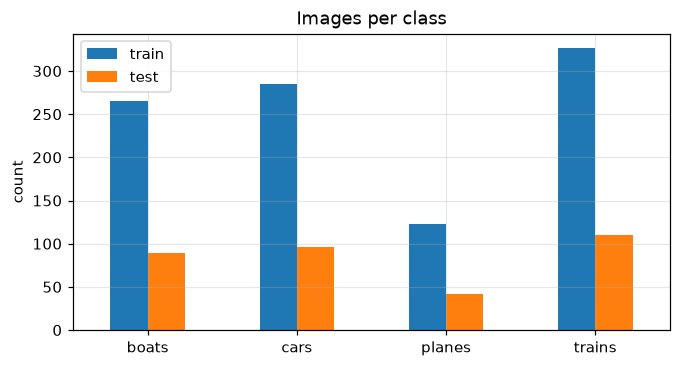

In [3]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp')
def list_images(split, cls):
    d = os.path.join(split, cls)
    return [os.path.join(d, f) for f in os.listdir(d) if f.lower().endswith(IMG_EXT)]

counts = pd.DataFrame({s: {c: len(list_images(s, c)) for c in ALL_CLASSES} for s in ['train', 'test']})
counts['total'] = counts.sum(axis=1)
counts['test_frac'] = (counts['test'] / counts['total']).round(3)
display(counts)

ax = counts[['train', 'test']].plot.bar(figsize=(7, 3.5), rot=0)
ax.set_title("Images per class"); ax.set_ylabel("count")
plt.show()

Print 6 random sample images for each class.

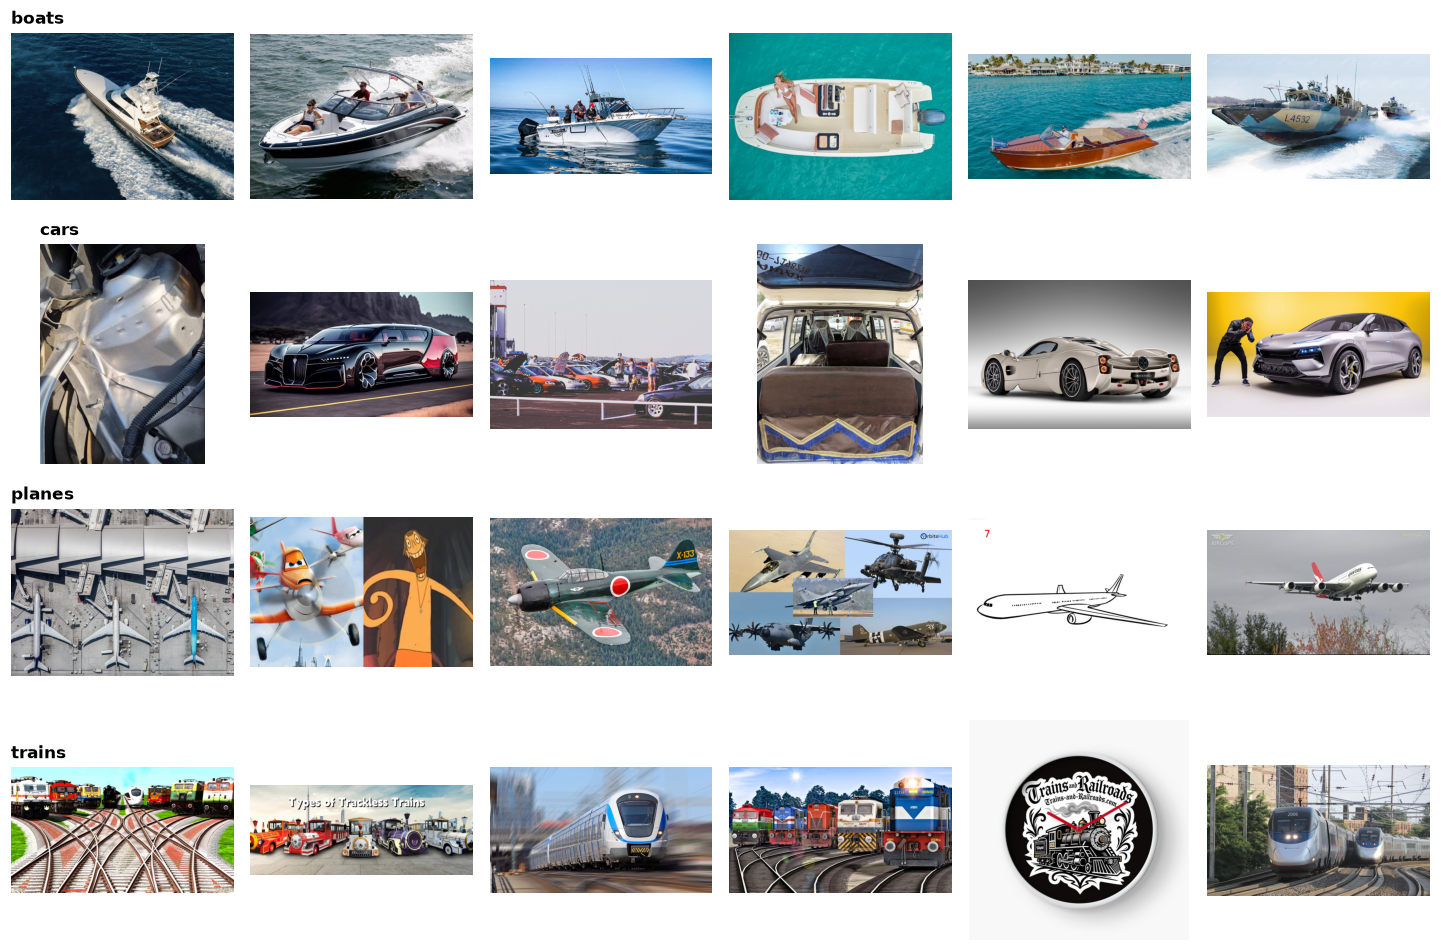

In [4]:
n = 6
fig, axes = plt.subplots(len(ALL_CLASSES), n, figsize=(2.2 * n, 2.2 * len(ALL_CLASSES)))
for i, c in enumerate(ALL_CLASSES):
    paths = random.sample(list_images('train', c), n)
    for j, p in enumerate(paths):
        axes[i, j].imshow(Image.open(p).convert('RGB'))
        axes[i, j].axis('off')
        if j == 0: axes[i, j].set_title(c, loc='left', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

Check for any corrupt images. Print file statistics for image size, aspect ratio, and number for each class and create plots as shown.

corrupt/unreadable files: 0


cls            boats    cars  planes  trains
w      count   354.0   381.0   165.0   437.0
       mean   1646.7  1523.7  1741.6  1379.2
       std    1093.4   852.4  1111.9   669.3
       min     236.0   372.0   471.0   239.0
       25%    1000.0   940.0  1024.0  1000.0
       50%    1280.0  1280.0  1344.0  1280.0
       75%    1973.8  1920.0  2000.0  1600.0
       max    6933.0  5760.0  6666.0  4820.0
h      count   354.0   381.0   165.0   437.0
       mean   1187.7  1019.0  1276.5   932.1
       std     806.4   510.4   869.6   478.0
       min     134.0   250.0   237.0   249.0
       25%     640.8   675.0   720.0   667.0
       50%     937.0   964.0  1080.0   750.0
       75%    1433.5  1080.0  1464.0  1080.0
       max    5184.0  3840.0  4716.0  3543.0
aspect count   354.0   381.0   165.0   437.0
       mean      1.5     1.5     1.5     1.5
       std       0.5     0.4     0.4     0.4
       min       0.2     0.4     0.6     0.6
       25%       1.3     1.4     1.2     1.4
       50%       1.5     1.8     1.5     1.6
       75%       1.8     1.8     1.8     1.8
       max       6.3     3.5     3.2     3.1

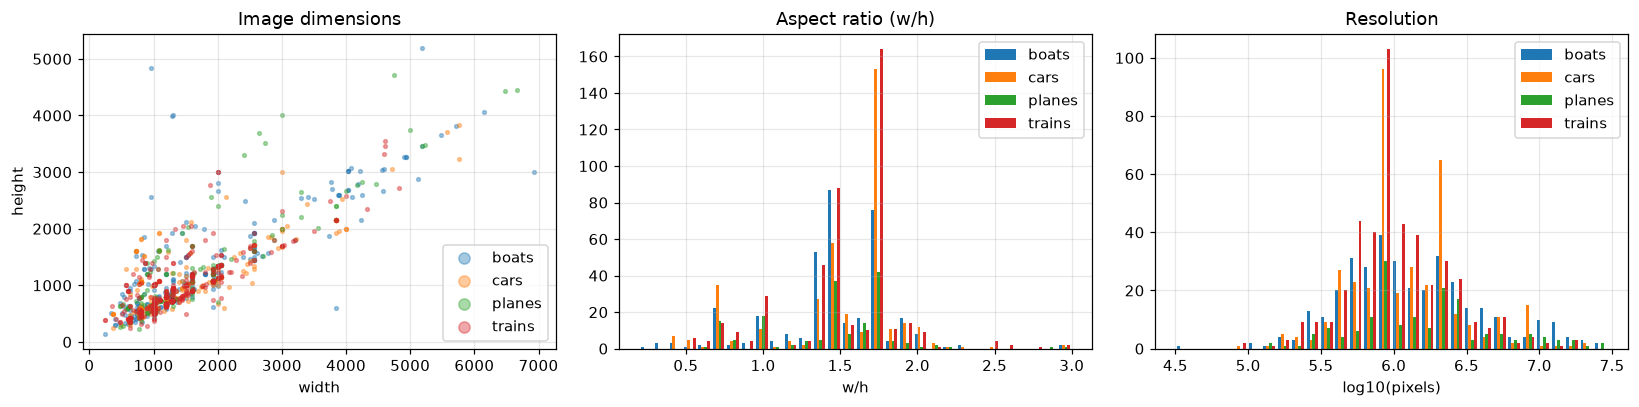

In [5]:
bad, rows = [], []
for s in ['train', 'test']:
    for c in ALL_CLASSES:
        for p in list_images(s, c):
            try:
                with Image.open(p) as im:
                    im.verify()
                with Image.open(p) as im:
                    w, h = im.size
                rows.append(dict(split=s, cls=c, w=w, h=h, path=p))
            except Exception as e:
                bad.append(p)
sizes = pd.DataFrame(rows)
sizes['aspect'] = sizes.w / sizes.h
print(f"corrupt/unreadable files: {len(bad)}")
for p in bad[:20]: print("  ", p)
display(sizes.groupby('cls')[['w', 'h', 'aspect']].describe().round(1).T)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for c in ALL_CLASSES:
    d = sizes[sizes.cls == c]
    ax[0].scatter(d.w, d.h, s=6, alpha=0.4, label=c)
ax[0].set(title="Image dimensions", xlabel="width", ylabel="height"); ax[0].legend(markerscale=3)
ax[1].hist([sizes[sizes.cls == c].aspect.clip(0, 3) for c in ALL_CLASSES], bins=30, label=ALL_CLASSES)
ax[1].set(title="Aspect ratio (w/h)", xlabel="w/h"); ax[1].legend()
ax[2].hist([np.log10(sizes[sizes.cls == c].w * sizes[sizes.cls == c].h) for c in ALL_CLASSES], bins=30, label=ALL_CLASSES)
ax[2].set(title="Resolution", xlabel="log10(pixels)"); ax[2].legend()
plt.tight_layout(); plt.show()

Check for near duplicates, since Bing can return the same image under different URL's. This would be the same filesize and dimensions. This is important since duplicates that cross over the train/test sets would cause a minor leak.

In [6]:
sizes['bytes'] = sizes.path.map(os.path.getsize)
dups = sizes[sizes.duplicated(['bytes', 'w', 'h'], keep=False)].sort_values('bytes')
print(f"{len(dups)} files share (bytes, width, height) with another file")
leak = dups.groupby(['bytes', 'w', 'h']).split.nunique()
print("duplicate groups spanning both train and test (leakage):", int((leak > 1).sum()))

5 files share (bytes, width, height) with another file
duplicate groups spanning both train and test (leakage): 1


## 3. Transforms and datasets
Random augmentations on training images only. Test images are only resized and converted to tensors. (The given code does not normalize with ImageNet statistics; we test that in Section 10.)

In [7]:
random_transform = transforms.Compose([
    transforms.RandomResizedCrop(256),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
    transforms.ToTensor()
])

common_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor()
])

Preview the same image under 9 random augmentations.

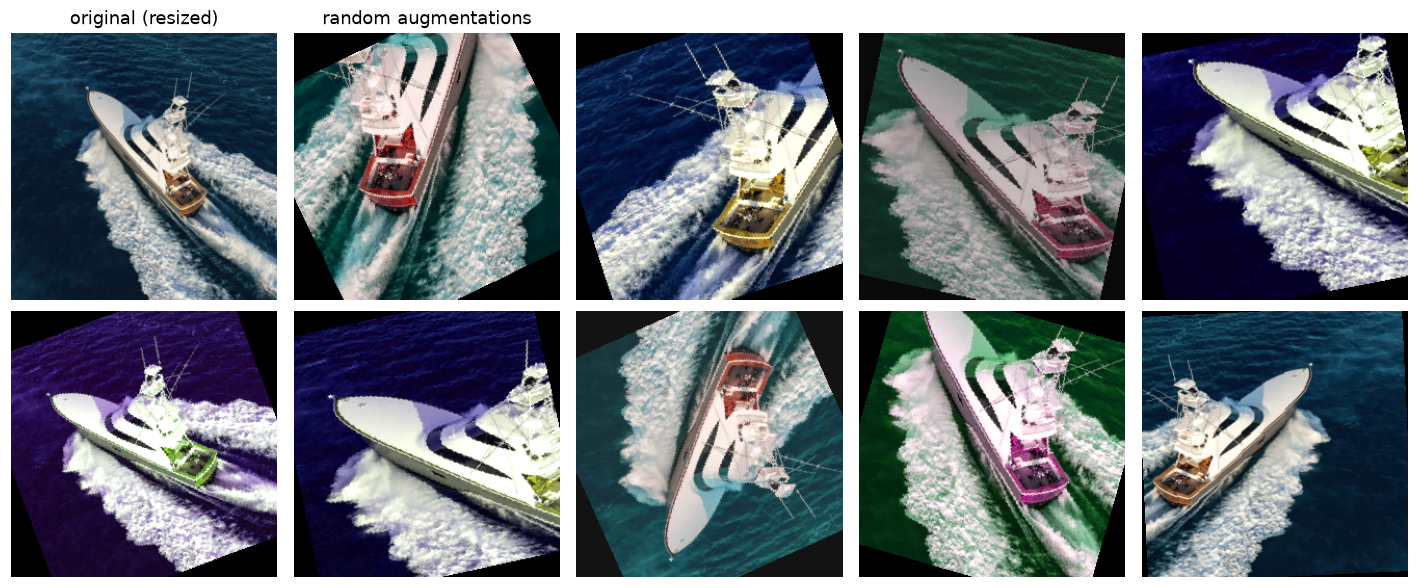

In [33]:
p = random.choice(list_images('train', ALL_CLASSES[0]))
img = Image.open(p).convert('RGB')
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
axes[0, 0].imshow(common_transform(img).permute(1, 2, 0)); axes[0, 0].set_title("original (resized)")
for a in axes.flat[1:]:
    a.imshow(random_transform(img).permute(1, 2, 0).clamp(0, 1))
for a in axes.flat: a.axis('off')
axes.flat[1].set_title("random augmentations")
plt.tight_layout(); plt.show()

### Dataset builder
The given code builds loaders directly from `ImageFolder`. `make_loaders` wraps that so experiments can (a) use a subset of the classes, (b) swap transforms, (c) use a fraction of the training data, and (d) carve a **validation split** out of `train/`. The validation set drives early stopping and model selection; the `test/` set is only for reporting.

In [9]:
def filter_classes(ds, classes):
    """Restrict an ImageFolder to `classes` and remap labels to 0..k-1."""
    keep = {ds.class_to_idx[c]: i for i, c in enumerate(classes)}
    ds.samples = [(p, keep[t]) for p, t in ds.samples if t in keep]
    ds.imgs = ds.samples
    ds.targets = [t for _, t in ds.samples]
    ds.classes = list(classes)
    ds.class_to_idx = {c: i for i, c in enumerate(classes)}
    return ds

def make_loaders(classes=None, train_tf=None, test_tf=None, val_frac=0.15, train_frac=1.0,
                 batch_size=BATCH_SIZE, num_workers=NUM_WORKERS):
    classes = list(classes) if classes is not None else ALL_CLASSES
    train_tf = random_transform if train_tf is None else train_tf
    test_tf  = common_transform if test_tf is None else test_tf

    tr_full  = filter_classes(datasets.ImageFolder(train_data_path, transform=train_tf), classes)
    val_full = filter_classes(datasets.ImageFolder(train_data_path, transform=test_tf), classes)  # same files, no augmentation
    test_ds  = filter_classes(datasets.ImageFolder(test_data_path,  transform=test_tf), classes)

    idx = np.random.RandomState(SEED).permutation(len(tr_full))
    n_val = int(val_frac * len(idx))
    val_idx, tr_idx = idx[:n_val], idx[n_val:]
    tr_idx = tr_idx[:max(1, int(len(tr_idx) * train_frac))]

    mk = lambda ds, shuffle: DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers)
    return dict(train=mk(Subset(tr_full, tr_idx), True), val=mk(Subset(val_full, val_idx), False),
                test=mk(test_ds, False), classes=classes, test_ds=test_ds,
                sizes=(len(tr_idx), len(val_idx), len(test_ds)))

L = make_loaders()
print("classes:", L['classes'], "| train/val/test sizes:", L['sizes'])

classes: ['boats', 'cars', 'planes', 'trains'] | train/val/test sizes: (850, 150, 336)


## 4. The model
ResNet18 with ImageNet weights, ~11M parameters. Freeze every pretrained parameter, then replace `model.fc` with a new randomly-initialized layer where only that layer trains. Print a diagram of the network below

In [10]:
def build_model(arch='resnet18', n_classes=4, hidden=0, dropout=0.0, act=nn.ReLU, unfreeze=()):

    model = torchvision.models.get_model(arch, weights='DEFAULT')
    for p in model.parameters():
        p.requires_grad = False 
    in_f = model.fc.in_features
    layers, d = [], in_f
    if hidden:
        if dropout: layers.append(nn.Dropout(dropout))
        layers += [nn.Linear(in_f, hidden), act()]
        d = hidden
    if dropout: layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(d, n_classes))
    model.fc = layers[0] if len(layers) == 1 else nn.Sequential(*layers)
    for name in unfreeze:
        for p in getattr(model, name).parameters():
            p.requires_grad = True
    return model.to(device)

pretrained = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
print(pretrained)
print("\nOriginal fc:", pretrained.fc)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

**Final output size:** the original `fc` is `Linear(512 -> 1000)` because ResNet18 was trained on ImageNet, which has 1000 classes (one logit per class). The 512 is the channel count of the last conv stage after global average pooling. We replace it with `Linear(512 -> n_classes)` so the output matches our task.

In [11]:
model = build_model(n_classes=len(ALL_CLASSES))
torchinfo.summary(model, input_size=(1, 3, 256, 256), depth=2,
                  col_names=("output_size", "num_params", "trainable"))

Layer (type:depth-idx)                   Output Shape              Param #                   Trainable
ResNet                                   [1, 4]                    --                        Partial
├─Conv2d: 1-1                            [1, 64, 128, 128]         (9,408)                   False
├─BatchNorm2d: 1-2                       [1, 64, 128, 128]         (128)                     False
├─ReLU: 1-3                              [1, 64, 128, 128]         --                        --
├─MaxPool2d: 1-4                         [1, 64, 64, 64]           --                        --
├─Sequential: 1-5                        [1, 64, 64, 64]           --                        False
│    └─BasicBlock: 2-1                   [1, 64, 64, 64]           (73,984)                  False
│    └─BasicBlock: 2-2                   [1, 64, 64, 64]           (73,984)                  False
├─Sequential: 1-6                        [1, 128, 32, 32]          --                        False
│    └─Bas

## 5. Helper functions
Training loop (same Adam + CrossEntropyLoss as the given code), evaluation, early stopping, plotting, and a one-call `run()` for experiments.

- Frozen backbone layers stay in `eval()` mode during training so the pretrained BatchNorm statistics aren't disturbed.
- Test accuracy is recorded every epoch **for plotting only**. Early stopping and "best epoch" use the validation split.

In [12]:
def set_train_mode(model):
    """train mode, except frozen blocks stay in eval (keeps pretrained BatchNorm stats fixed)."""
    model.train()
    for m in model.children():
        params = list(m.parameters())
        if params and not any(p.requires_grad for p in params):
            m.eval()

@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    loss_sum, n, preds, targets, probs = 0.0, 0, [], [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        if criterion is not None:
            loss_sum += criterion(out, y).item() * len(y)
        pr = out.softmax(1)
        preds.append(pr.argmax(1).cpu()); targets.append(y.cpu()); probs.append(pr.cpu())
        n += len(y)
    preds, targets, probs = torch.cat(preds).numpy(), torch.cat(targets).numpy(), torch.cat(probs).numpy()
    return dict(loss=loss_sum / n, acc=(preds == targets).mean(), preds=preds, targets=targets, probs=probs)

def train_model(model, L, epochs=20, lr=1e-3, patience=None, verbose=True, label=''):
    criterion = nn.CrossEntropyLoss()
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(params, lr=lr)
    h = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'test_loss', 'test_acc', 'epoch_time']}
    h['trainable'] = sum(p.numel() for p in params)
    best, best_ep, best_state, bad, t0 = float('inf'), 1, None, 0, time.time()

    for ep in range(1, epochs + 1):
        te = time.time()
        set_train_mode(model)
        loss_sum, correct, n = 0.0, 0, 0
        for data, target in L['train']:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(target); n += len(target)
            correct += (output.argmax(1) == target).sum().item()
        v, t = evaluate(model, L['val'], criterion), evaluate(model, L['test'], criterion)
        for k, val in [('train_loss', loss_sum / n), ('train_acc', correct / n), ('val_loss', v['loss']),
                       ('val_acc', v['acc']), ('test_loss', t['loss']), ('test_acc', t['acc']),
                       ('epoch_time', time.time() - te)]:
            h[k].append(val)
        if verbose:
            print(f"[{label}] epoch {ep:2d} | train {h['train_loss'][-1]:.3f}/{h['train_acc'][-1]:.3f} "
                  f"| val {v['loss']:.3f}/{v['acc']:.3f} | test acc {t['acc']:.3f}")
        if v['loss'] < best - 1e-4:
            best, best_ep, bad = v['loss'], ep, 0
            if patience: best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if patience and bad >= patience:
                if verbose: print(f"[{label}] early stop at epoch {ep} (best epoch {best_ep})")
                break
    if patience and best_state is not None:
        model.load_state_dict(best_state)         # restore best weights
    h['best_epoch'], h['time'] = best_ep, time.time() - t0
    h['stopped_early'] = len(h['val_loss']) < epochs
    if not verbose:
        print(f"[{label}] done in {h['time']:.0f}s | best epoch {best_ep} | test acc @best-val {h['test_acc'][best_ep-1]:.3f}")
    return h

def run(label, classes=None, train_tf=None, test_tf=None, epochs=None, lr=1e-3, train_frac=1.0,
        patience=None, arch='resnet18', verbose=False, **model_kw):
    seed_everything()
    Lr = make_loaders(classes, train_tf, test_tf, train_frac=train_frac)
    m = build_model(arch, len(Lr['classes']), **model_kw)
    h = train_model(m, Lr, epochs or EXP_EPOCHS, lr, patience, verbose, label)
    return m, h, Lr

In [13]:
def plot_history(h, title=''):
    ep = np.arange(1, len(h['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for k, c in [('train', 'C0'), ('val', 'C1'), ('test', 'C2')]:
        ax[0].plot(ep, h[f'{k}_loss'], label=k, color=c, marker='o', ms=3)
        ax[1].plot(ep, h[f'{k}_acc'],  label=k, color=c, marker='o', ms=3)
    for a, name in zip(ax, ['Loss', 'Accuracy']):
        a.axvline(h['best_epoch'], color='gray', ls='--', lw=1, label=f"best val epoch ({h['best_epoch']})")
        a.set(title=f"{title} {name}", xlabel='epoch'); a.legend()
    plt.tight_layout(); plt.show()

def compare(results, metrics=('train_loss', 'val_acc', 'test_acc'), title=''):
    """Overlay several runs. results: {label: history}"""
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4))
    for ax, m in zip(np.atleast_1d(axes), metrics):
        for lab, h in results.items():
            ax.plot(range(1, len(h[m]) + 1), h[m], marker='o', ms=3, label=str(lab))
        ax.set(title=f"{title} {m}", xlabel='epoch'); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

def summarize(results):
    rows = []
    for lab, h in results.items():
        b = h['best_epoch'] - 1
        conv = next((i + 1 for i, a in enumerate(h['val_acc']) if a >= max(h['val_acc']) - 0.01), len(h['val_acc']))
        rows.append({'run': lab, 'trainable_params': h['trainable'], 'epochs_run': len(h['val_acc']),
                     'best_epoch': h['best_epoch'], 'epochs_to_converge': conv,
                     'train_acc(last)': h['train_acc'][-1], 'val_acc(best)': max(h['val_acc']),
                     'test_acc(last)': h['test_acc'][-1], 'test_acc@best_val': h['test_acc'][b],
                     'train-test gap': h['train_acc'][-1] - h['test_acc'][-1],
                     'sec/epoch': np.mean(h['epoch_time']), 'total_sec': h['time']})
    return pd.DataFrame(rows).set_index('run').round(4)

def report(model, Lr, title=''):
    r = evaluate(model, Lr['test'])
    cls = Lr['classes']
    cm = confusion_matrix(r['targets'], r['preds'])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ConfusionMatrixDisplay(cm, display_labels=cls).plot(ax=ax[0], cmap='Blues', colorbar=False)
    ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=cls).plot(
        ax=ax[1], cmap='Blues', colorbar=False, values_format='.2f')
    ax[0].set_title(f"{title} confusion (counts)"); ax[1].set_title("row-normalized (recall)")
    for a in ax: a.grid(False)
    plt.tight_layout(); plt.show()
    print(classification_report(r['targets'], r['preds'], target_names=cls, digits=3))
    return r

def show_mistakes(r, Lr, n=8):
    paths = [p for p, _ in Lr['test_ds'].samples]
    wrong = np.where(r['preds'] != r['targets'])[0]
    if len(wrong) == 0:
        print("No mistakes!"); return
    wrong = wrong[np.argsort(-r['probs'][wrong].max(1))][:n]
    cols = min(4, len(wrong)); rows = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.4 * rows))
    for a in np.atleast_1d(axes).flat: a.axis('off')
    for a, i in zip(np.atleast_1d(axes).flat, wrong):
        a.imshow(Image.open(paths[i]).convert('RGB'))
        a.set_title(f"true: {Lr['classes'][r['targets'][i]]}\npred: {Lr['classes'][r['preds'][i]]} ({r['probs'][i].max():.2f})",
                    fontsize=9, color='firebrick')
    plt.suptitle("Most confident mistakes"); plt.tight_layout(); plt.show()

## 6. Baseline: the given code
ResNet18, frozen backbone, single `Linear(512 -> k)` head, Adam lr=1e-3, the given augmentations, 20 epochs.

[baseline] epoch  1 | train 1.285/0.398 | val 1.038/0.600 | test acc 0.637
[baseline] epoch  2 | train 1.058/0.556 | val 0.780/0.707 | test acc 0.759
[baseline] epoch  3 | train 0.926/0.656 | val 0.630/0.800 | test acc 0.842
[baseline] epoch  4 | train 0.866/0.655 | val 0.541/0.833 | test acc 0.896
[baseline] epoch  5 | train 0.796/0.718 | val 0.565/0.787 | test acc 0.872
[baseline] epoch  6 | train 0.774/0.704 | val 0.504/0.820 | test acc 0.869
[baseline] epoch  7 | train 0.744/0.720 | val 0.499/0.813 | test acc 0.899
[baseline] epoch  8 | train 0.741/0.722 | val 0.469/0.813 | test acc 0.899
[baseline] epoch  9 | train 0.722/0.725 | val 0.442/0.847 | test acc 0.887
[baseline] epoch 10 | train 0.693/0.742 | val 0.444/0.833 | test acc 0.905
[baseline] epoch 11 | train 0.654/0.765 | val 0.428/0.847 | test acc 0.899
[baseline] epoch 12 | train 0.644/0.760 | val 0.403/0.873 | test acc 0.896
[baseline] epoch 13 | train 0.637/0.776 | val 0.415/0.840 | test acc 0.902
[baseline] epoch 14 | tra

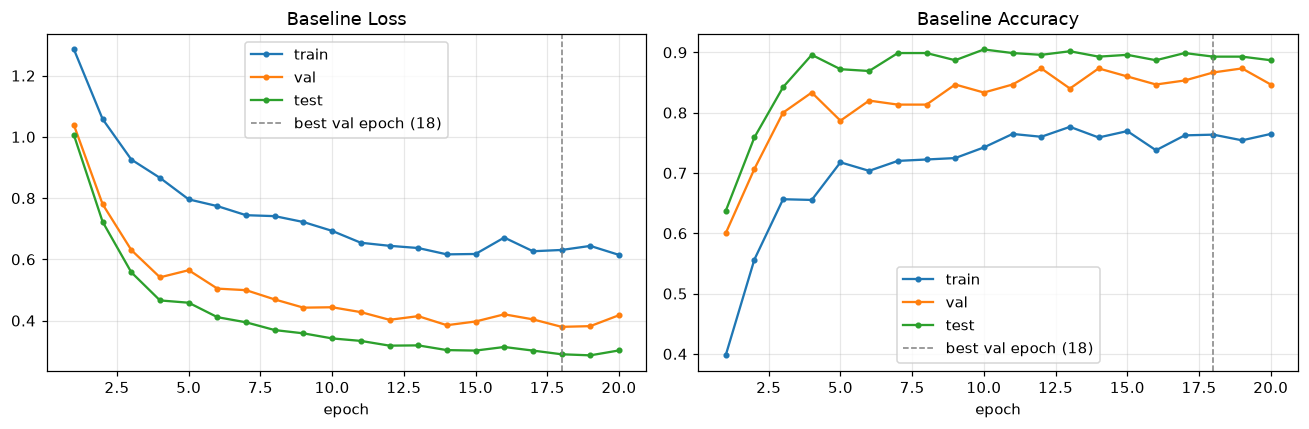

Test Accuracy (final epoch): 88.69%


In [14]:
import warnings

# Mute only the Pillow palette transparency warning
warnings.filterwarnings(
    "ignore", 
    category=UserWarning, 
    message=r".*Palette images with Transparency.*"
)

base_model, base_h, base_L = run('baseline', epochs=20, verbose=True)
plot_history(base_h, 'Baseline')
print(f"Test Accuracy (final epoch): {base_h['test_acc'][-1] * 100:.2f}%")

### Confusion matrix, per-class metrics, mistakes

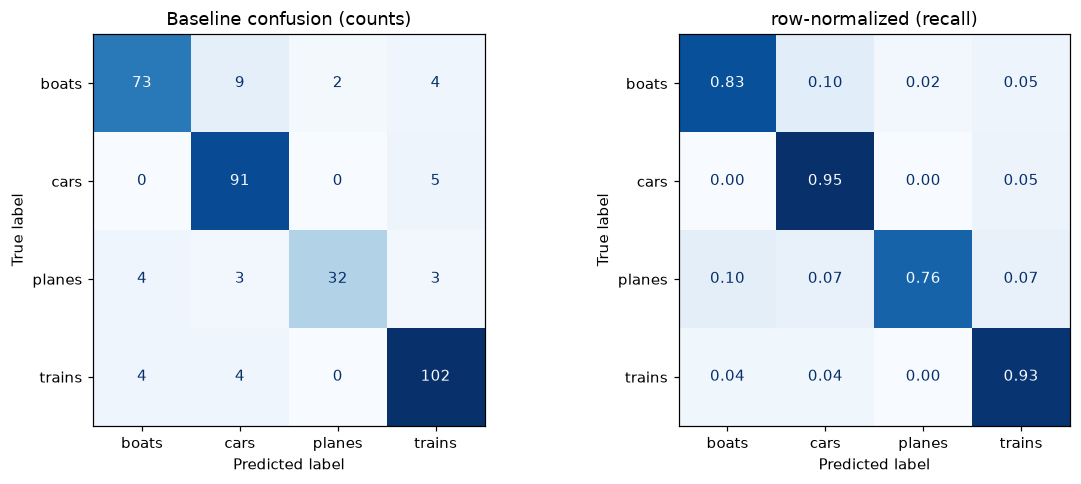

              precision    recall  f1-score   support

       boats      0.901     0.830     0.864        88
        cars      0.850     0.948     0.897        96
      planes      0.941     0.762     0.842        42
      trains      0.895     0.927     0.911       110

    accuracy                          0.887       336
   macro avg      0.897     0.867     0.878       336
weighted avg      0.890     0.887     0.886       336



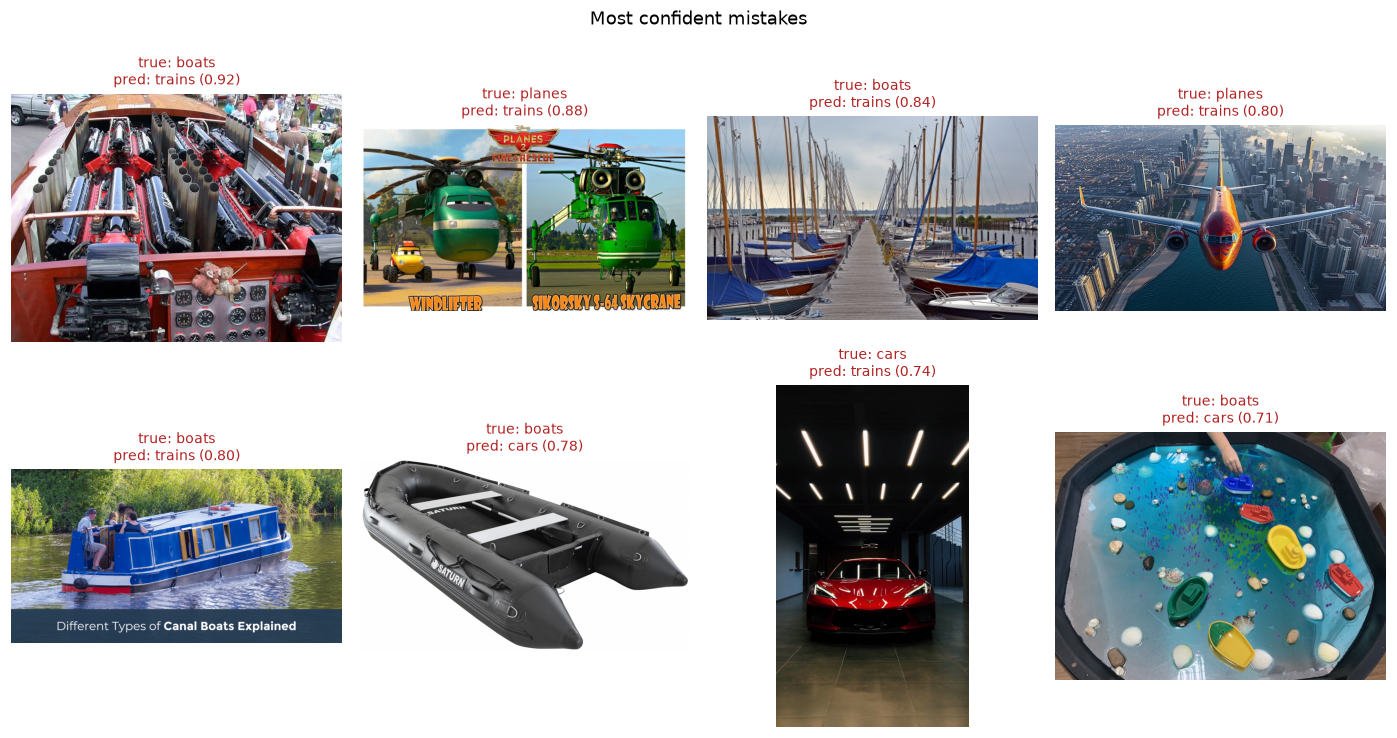

In [15]:
r = report(base_model, base_L, 'Baseline')
show_mistakes(r, base_L)

How confident is the model when it is right vs wrong?

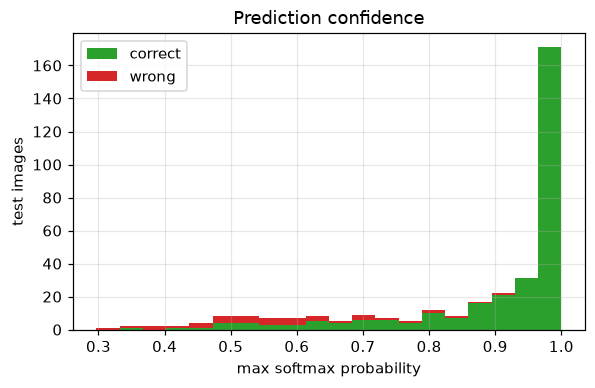

In [16]:
conf = r['probs'].max(1); ok = r['preds'] == r['targets']
plt.figure(figsize=(6, 3.5))
plt.hist([conf[ok], conf[~ok]], bins=20, label=['correct', 'wrong'], stacked=True, color=['C2', 'C3'])
plt.xlabel("max softmax probability"); plt.ylabel("test images"); plt.title("Prediction confidence"); plt.legend(); plt.show()

### What do the frozen features look like?
Take the 512-d features from the pretrained backbone (before the new head), project to 2D with PCA and t-SNE. Clean clusters mean linear will do well; overlapping clusters predict confusion.

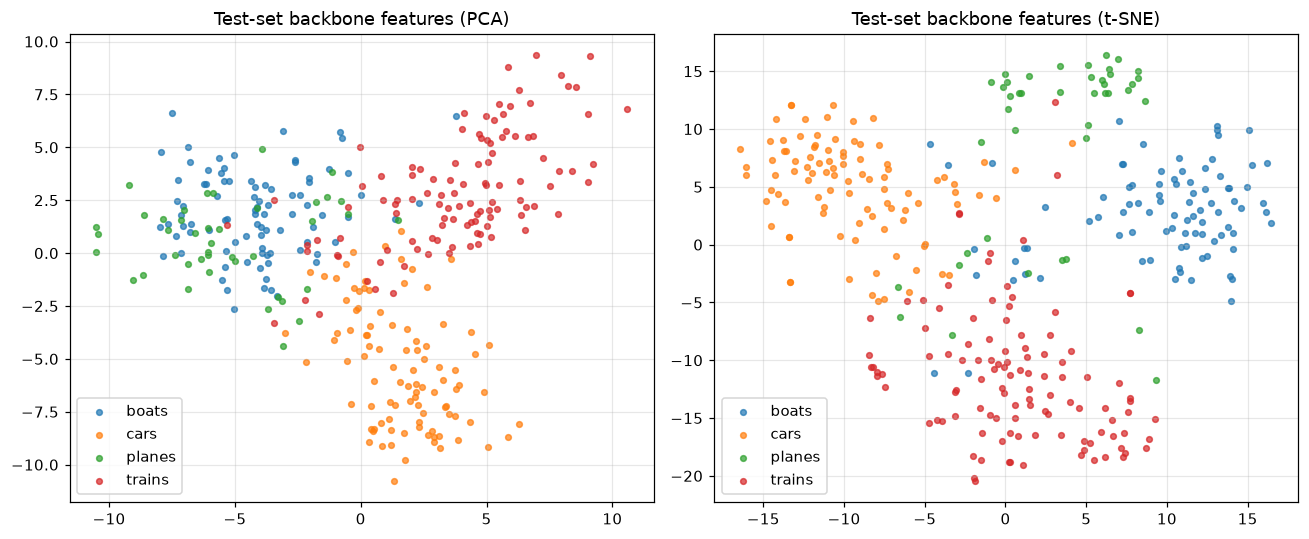

In [17]:
@torch.no_grad()
def extract_features(model, loader):
    fe = copy.deepcopy(model); fe.fc = nn.Identity(); fe.eval()
    F, Y = [], []
    for x, y in loader:
        F.append(fe(x.to(device)).cpu()); Y.append(y)
    return torch.cat(F).numpy(), torch.cat(Y).numpy()

feats, ys = extract_features(base_model, base_L['test'])
pca2 = PCA(2, random_state=SEED).fit_transform(feats)
tsne2 = TSNE(2, perplexity=min(30, len(feats) - 1), init='pca', random_state=SEED).fit_transform(feats)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, emb, name in zip(ax, [pca2, tsne2], ['PCA', 't-SNE']):
    for i, c in enumerate(base_L['classes']):
        a.scatter(*emb[ys == i].T, s=14, alpha=0.7, label=c)
    a.set_title(f"Test-set backbone features ({name})"); a.legend()
plt.tight_layout(); plt.show()

## 7. Q1: How does adding more classes affect performance? Which classes are hard to tell apart?

**(a)** Train with the first 2, 3, then all classes. **(b)** Train a binary classifier for every pair to find the hardest pairs.

[2 classes] done in 110s | best epoch 10 | test acc @best-val 0.946
[3 classes] done in 118s | best epoch 10 | test acc @best-val 0.907
[4 classes] done in 133s | best epoch 9 | test acc @best-val 0.887


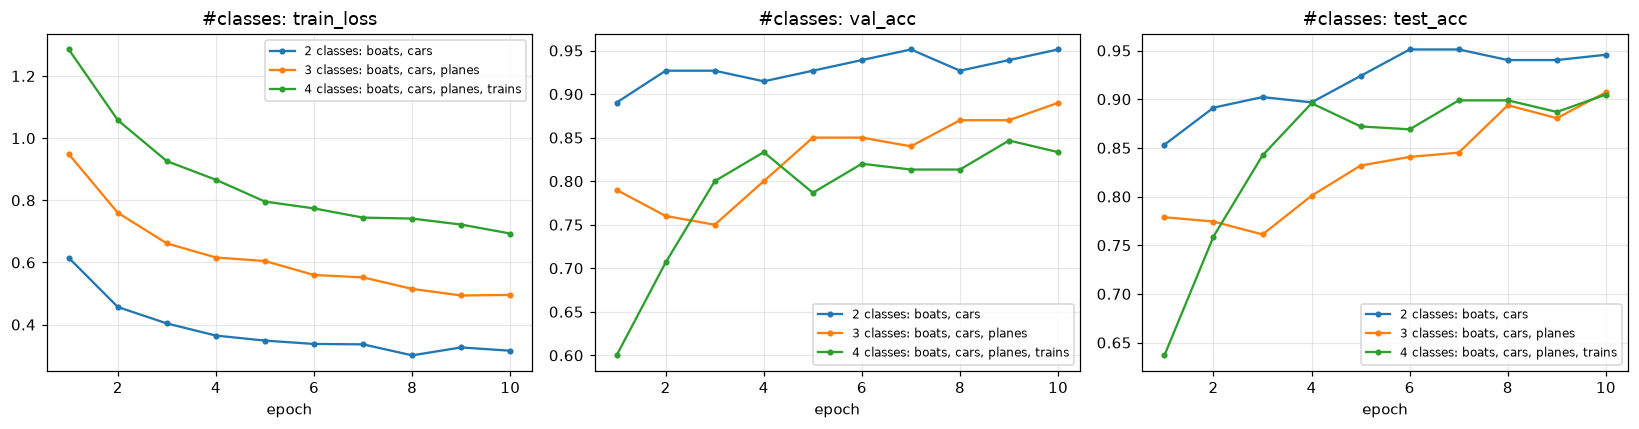

,trainable_params,epochs_run,best_epoch,epochs_to_converge,train_acc(last),val_acc(best),test_acc(last),test_acc@best_val,train-test gap,sec/epoch,total_sec
run,,,,,,,,,,,
"2 classes: boats, cars",1026,10,10,7,0.8803,0.9512,0.9457,0.9457,-0.0653,10.9538,109.5384
"3 classes: boats, cars, planes",1539,10,10,10,0.8028,0.8900,0.9071,0.9071,-0.1043,11.7970,117.9703
"4 classes: boats, cars, planes, trains",2052,10,9,9,0.7424,0.8467,0.9048,0.8869,-0.1624,13.2840,132.8402


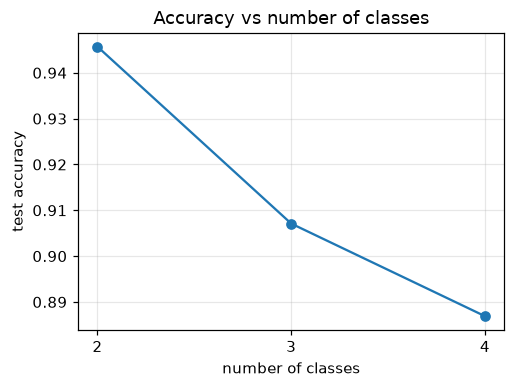

In [18]:
class_runs = {}
for k in range(2, len(ALL_CLASSES) + 1):
    _, h, _ = run(f'{k} classes', classes=ALL_CLASSES[:k])
    class_runs[f'{k} classes: {", ".join(ALL_CLASSES[:k])}'] = h
compare(class_runs, title='#classes:')
tab = summarize(class_runs); display(tab)

plt.figure(figsize=(5, 3.5))
plt.plot(range(2, len(ALL_CLASSES) + 1), tab['test_acc@best_val'], marker='o')
plt.xticks(range(2, len(ALL_CLASSES) + 1)); plt.xlabel("number of classes"); plt.ylabel("test accuracy")
plt.title("Accuracy vs number of classes"); plt.show()

Train every pair of classes as its own binary problem (only 2 items being compared). Do all combinations except (x vs x) (same two items).

[boats vs cars] done in 110s | best epoch 10 | test acc @best-val 0.946
[boats vs planes] done in 102s | best epoch 10 | test acc @best-val 0.900
[boats vs trains] done in 106s | best epoch 10 | test acc @best-val 0.944
[cars vs planes] done in 90s | best epoch 10 | test acc @best-val 0.935
[cars vs trains] done in 94s | best epoch 10 | test acc @best-val 0.971
[planes vs trains] done in 91s | best epoch 10 | test acc @best-val 0.961


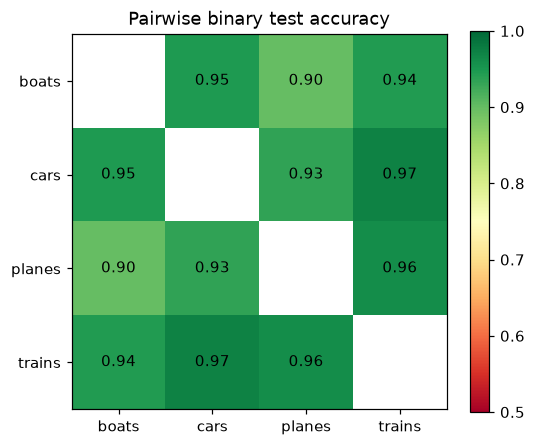

Hardest pairs:


,a,b,acc
2,boats,planes,0.900000
6,cars,planes,0.934783
3,boats,trains,0.944444


In [19]:
pair_acc = pd.DataFrame(np.nan, index=ALL_CLASSES, columns=ALL_CLASSES)
for a, b in itertools.combinations(ALL_CLASSES, 2):
    _, h, _ = run(f'{a} vs {b}', classes=[a, b])
    pair_acc.loc[a, b] = pair_acc.loc[b, a] = h['test_acc'][h['best_epoch'] - 1]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(pair_acc.values.astype(float), cmap='RdYlGn', vmin=0.5, vmax=1.0)
ax.set_xticks(range(len(ALL_CLASSES))); ax.set_xticklabels(ALL_CLASSES)
ax.set_yticks(range(len(ALL_CLASSES))); ax.set_yticklabels(ALL_CLASSES); ax.grid(False)
for i in range(len(ALL_CLASSES)):
    for j in range(len(ALL_CLASSES)):
        if i != j: ax.text(j, i, f"{pair_acc.values[i, j]:.2f}", ha='center', va='center')
plt.colorbar(im); ax.set_title("Pairwise binary test accuracy"); plt.show()

pairs = pair_acc.stack().reset_index(); pairs.columns = ['a', 'b', 'acc']
pairs = pairs[pairs.a < pairs.b].sort_values('acc')
print("Hardest pairs:"); display(pairs.head(3))

**Reading the results:** Boats to planes, cars to planes, and boats to trains had the hardest comparison. 

## 8. Q2: Depth, width, dropout, activation, and fine-tuning

### 8a. Backbone depth: ResNet18 vs 34 vs 50
Deeper backbones give richer features but are slower, and the head input size changes (512 -> 512 -> 2048).

[resnet18] done in 132s | best epoch 9 | test acc @best-val 0.887
[resnet34] done in 135s | best epoch 10 | test acc @best-val 0.899
[resnet50] done in 136s | best epoch 10 | test acc @best-val 0.949


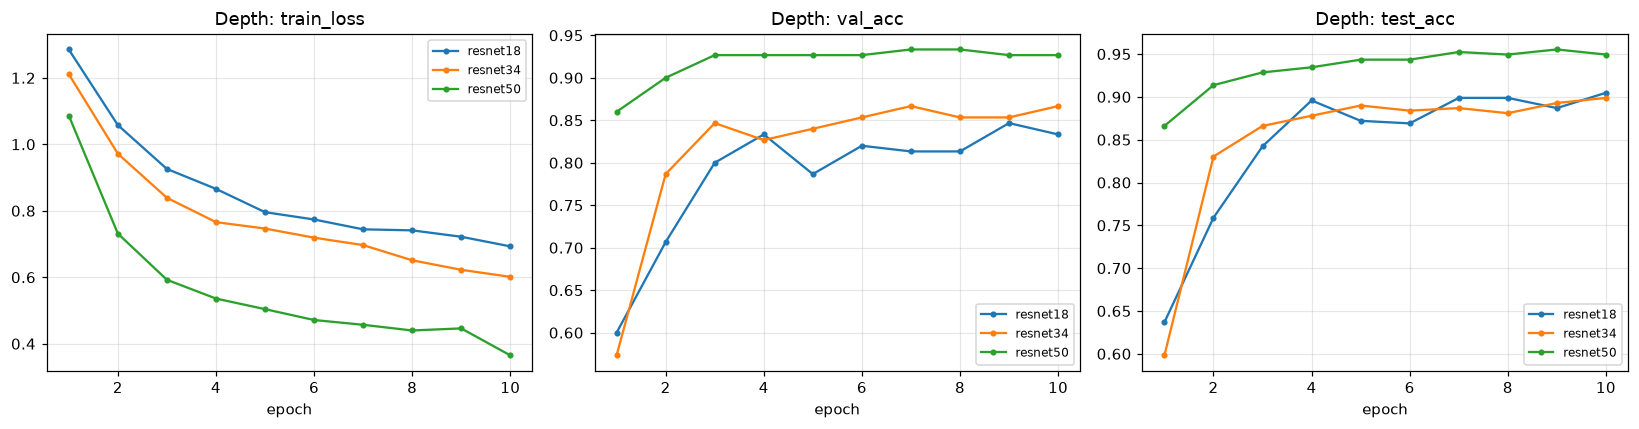

,trainable_params,epochs_run,best_epoch,epochs_to_converge,train_acc(last),val_acc(best),test_acc(last),test_acc@best_val,train-test gap,sec/epoch,total_sec
run,,,,,,,,,,,
resnet18,2052,10,9,9,0.7424,0.8467,0.9048,0.8869,-0.1624,13.1877,131.8774
resnet34,2052,10,10,7,0.7847,0.8667,0.8988,0.8988,-0.1141,13.5098,135.0979
resnet50,8196,10,10,3,0.8859,0.9333,0.9494,0.9494,-0.0635,13.5573,135.5731


In [20]:
depth_runs = {}
for arch in ['resnet18', 'resnet34', 'resnet50']:
    _, h, _ = run(arch, arch=arch)
    depth_runs[arch] = h
compare(depth_runs, title='Depth:')
display(summarize(depth_runs))

### 8b. Head design: width, dropout, activation
`hidden=0` is the given single-linear head. Others add a hidden layer.

[hidden=0] done in 132s | best epoch 9 | test acc @best-val 0.887
[hidden=64] done in 133s | best epoch 9 | test acc @best-val 0.911
[hidden=256] done in 132s | best epoch 7 | test acc @best-val 0.902
[hidden=1024] done in 134s | best epoch 7 | test acc @best-val 0.902


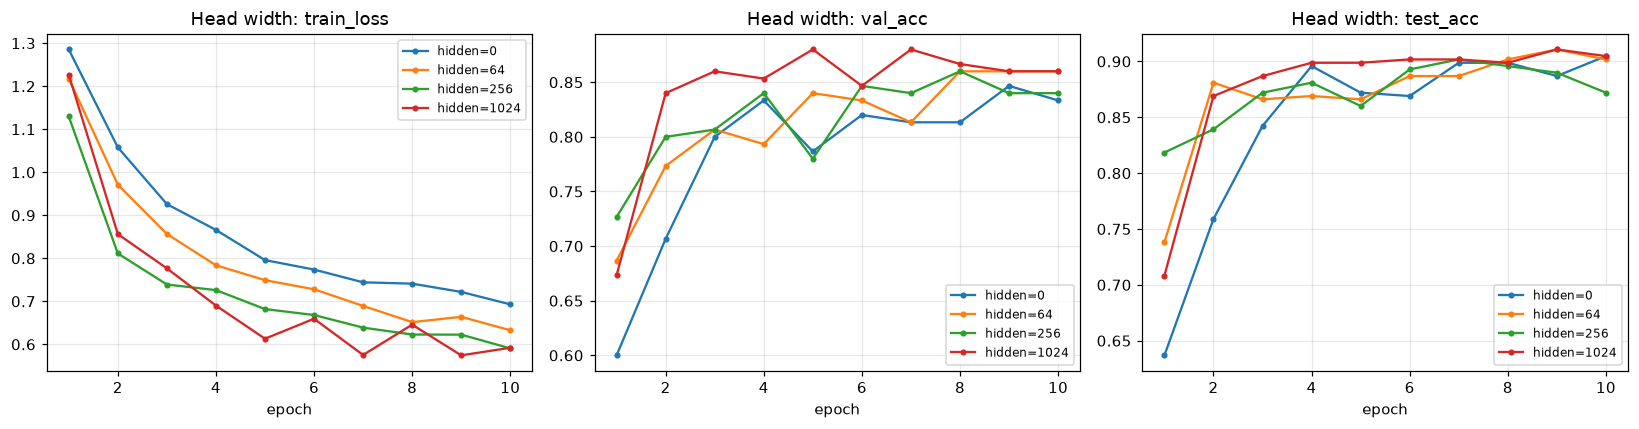

,trainable_params,epochs_run,best_epoch,epochs_to_converge,train_acc(last),val_acc(best),test_acc(last),test_acc@best_val,train-test gap,sec/epoch,total_sec
run,,,,,,,,,,,
hidden=0,2052,10,9,9,0.7424,0.8467,0.9048,0.8869,-0.1624,13.2384,132.3844
hidden=64,33092,10,9,8,0.7553,0.8600,0.9018,0.9107,-0.1465,13.3195,133.1951
hidden=256,132356,10,7,8,0.7671,0.8600,0.8720,0.9018,-0.1050,13.2294,132.2942
hidden=1024,529412,10,7,5,0.7659,0.8800,0.9048,0.9018,-0.1389,13.4334,134.3341


In [21]:
head_runs = {}
for hidden in [0, 64, 256, 1024]:
    _, h, _ = run(f'hidden={hidden}', hidden=hidden)
    head_runs[f'hidden={hidden}'] = h
compare(head_runs, title='Head width:')
display(summarize(head_runs))

[dropout=0.0] done in 132s | best epoch 7 | test acc @best-val 0.902
[dropout=0.2] done in 132s | best epoch 6 | test acc @best-val 0.899
[dropout=0.5] done in 133s | best epoch 9 | test acc @best-val 0.890
[dropout=0.7] done in 133s | best epoch 10 | test acc @best-val 0.866


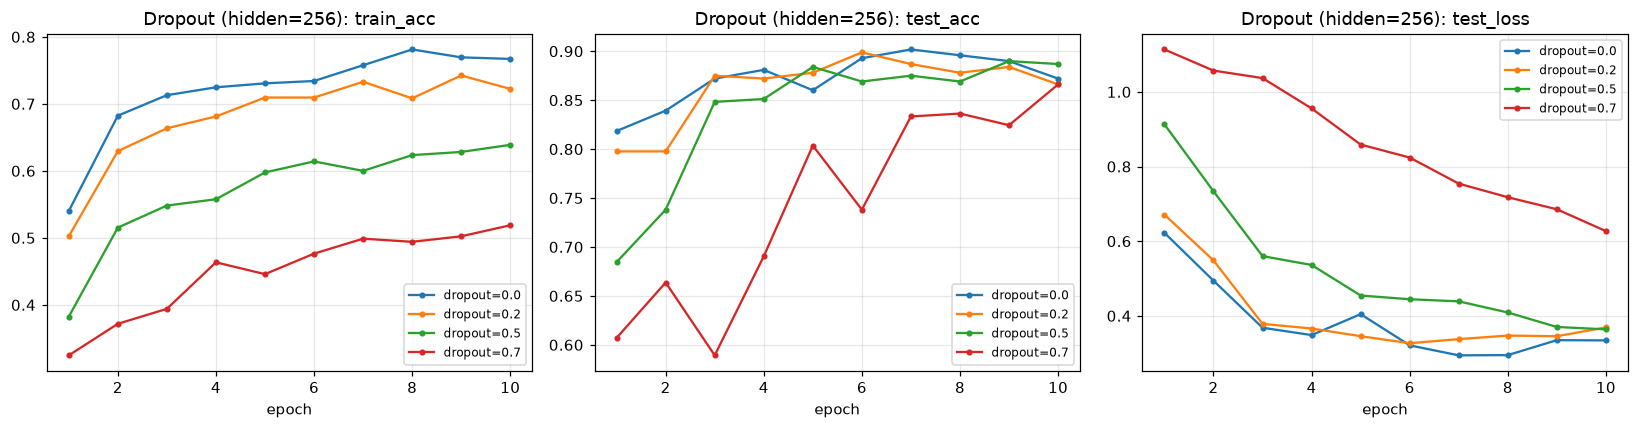

,trainable_params,epochs_run,best_epoch,epochs_to_converge,train_acc(last),val_acc(best),test_acc(last),test_acc@best_val,train-test gap,sec/epoch,total_sec
run,,,,,,,,,,,
dropout=0.0,132356,10,7,8,0.7671,0.8600,0.8720,0.9018,-0.1050,13.2199,132.1991
dropout=0.2,132356,10,6,6,0.7224,0.8600,0.8661,0.8988,-0.1437,13.2466,132.4659
dropout=0.5,132356,10,9,9,0.6388,0.8467,0.8869,0.8899,-0.2481,13.2786,132.7860
dropout=0.7,132356,10,10,9,0.5188,0.7800,0.8661,0.8661,-0.3472,13.2628,132.6277


In [22]:
drop_runs = {}
for p in [0.0, 0.2, 0.5, 0.7]:
    _, h, _ = run(f'dropout={p}', hidden=256, dropout=p)
    drop_runs[f'dropout={p}'] = h
compare(drop_runs, metrics=('train_acc', 'test_acc', 'test_loss'), title='Dropout (hidden=256):')
display(summarize(drop_runs))

Compare a wide varity of activation functions: ReLU, LeakyReLU, GELU, Tanh, Sigmoid.

[act=ReLU] done in 132s | best epoch 7 | test acc @best-val 0.902
[act=LeakyReLU] done in 132s | best epoch 8 | test acc @best-val 0.899
[act=GELU] done in 133s | best epoch 7 | test acc @best-val 0.899
[act=Tanh] done in 133s | best epoch 6 | test acc @best-val 0.896
[act=Sigmoid] done in 133s | best epoch 9 | test acc @best-val 0.890


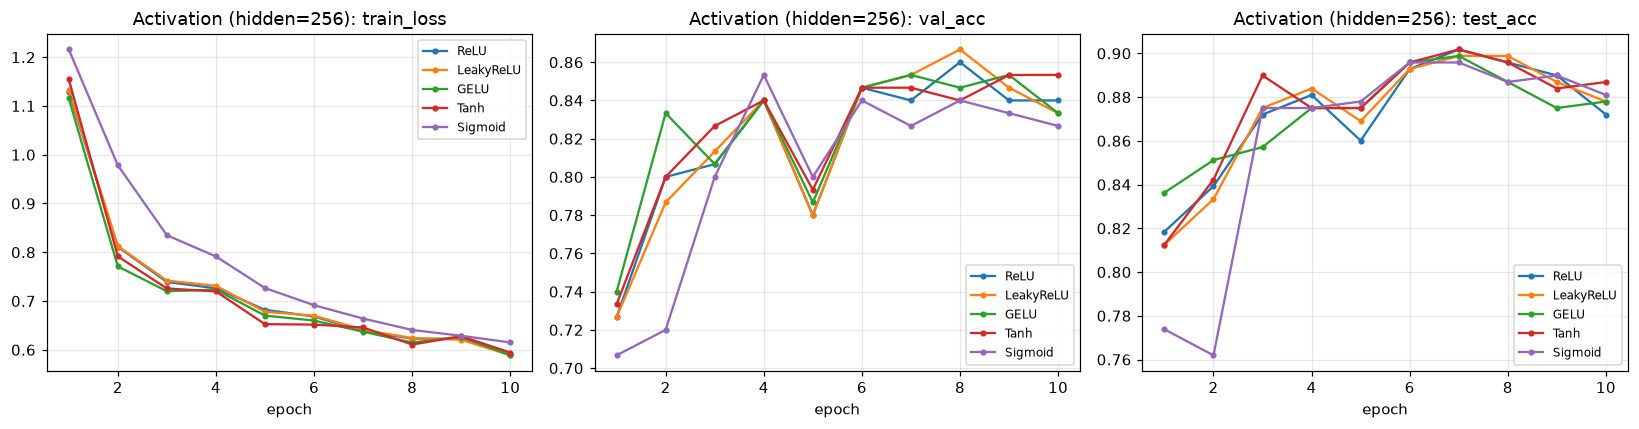

,trainable_params,epochs_run,best_epoch,epochs_to_converge,train_acc(last),val_acc(best),test_acc(last),test_acc@best_val,train-test gap,sec/epoch,total_sec
run,,,,,,,,,,,
ReLU,132356,10,7,8,0.7671,0.8600,0.8720,0.9018,-0.1050,13.2072,132.0716
LeakyReLU,132356,10,8,8,0.7682,0.8667,0.8780,0.8988,-0.1097,13.2269,132.2694
GELU,132356,10,7,6,0.7647,0.8533,0.8780,0.8988,-0.1133,13.2530,132.5296
Tanh,132356,10,6,6,0.7635,0.8533,0.8869,0.8958,-0.1234,13.2778,132.7776
Sigmoid,132356,10,9,4,0.7624,0.8533,0.8810,0.8899,-0.1186,13.2753,132.7529


In [23]:
act_runs = {}
for name, act in [('ReLU', nn.ReLU), ('LeakyReLU', nn.LeakyReLU), ('GELU', nn.GELU), ('Tanh', nn.Tanh), ('Sigmoid', nn.Sigmoid)]:
    _, h, _ = run(f'act={name}', hidden=256, act=act)
    act_runs[name] = h
compare(act_runs, title='Activation (hidden=256):')
display(summarize(act_runs))

### 8c. Fine-tuning more than the head
Unfreeze the last ResNet stage(s), with a smaller learning rate so the pretrained weights aren't wrecked. This goes beyond pure transfer learning but is a common next step.

[head only] done in 132s | best epoch 9 | test acc @best-val 0.887
[+layer4] done in 132s | best epoch 6 | test acc @best-val 0.932
[+layer3,4] done in 132s | best epoch 7 | test acc @best-val 0.896


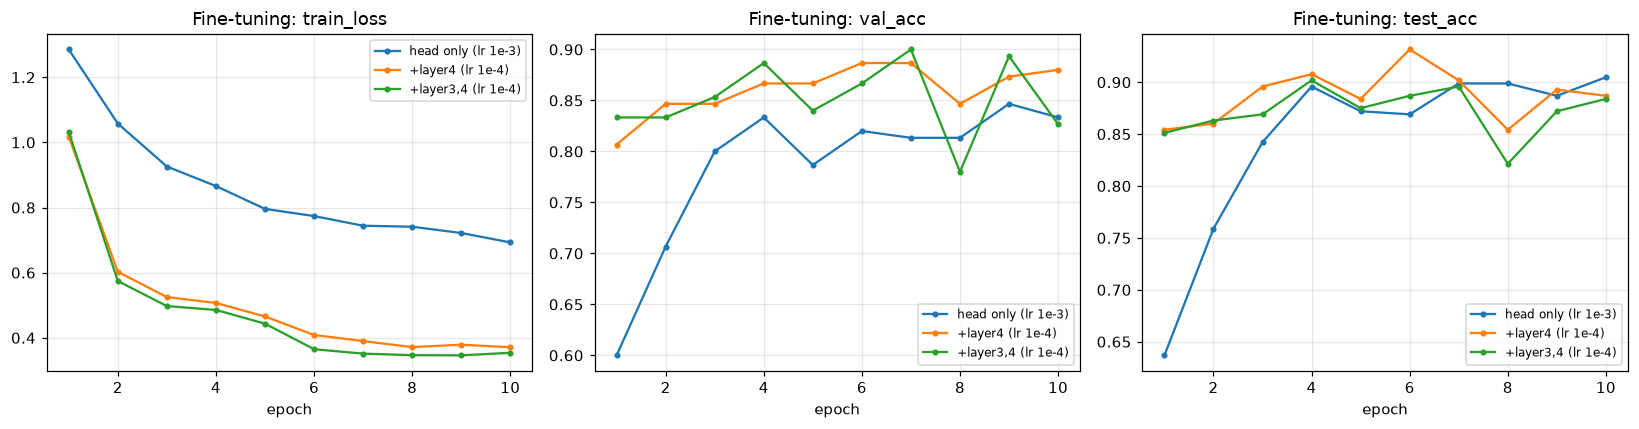

,trainable_params,epochs_run,best_epoch,epochs_to_converge,train_acc(last),val_acc(best),test_acc(last),test_acc@best_val,train-test gap,sec/epoch,total_sec
run,,,,,,,,,,,
head only (lr 1e-3),2052,10,9,9,0.7424,0.8467,0.9048,0.8869,-0.1624,13.1777,131.7769
+layer4 (lr 1e-4),8395780,10,6,6,0.8565,0.8867,0.8869,0.9315,-0.0304,13.1642,131.6418
"+layer3,4 (lr 1e-4)",10495492,10,7,7,0.8671,0.9000,0.8839,0.8958,-0.0169,13.1834,131.8344


In [24]:
ft_runs = {}
_, ft_runs['head only (lr 1e-3)'], _ = run('head only')
_, ft_runs['+layer4 (lr 1e-4)'], _ = run('+layer4', lr=1e-4, unfreeze=('layer4',))
_, ft_runs['+layer3,4 (lr 1e-4)'], _ = run('+layer3,4', lr=1e-4, unfreeze=('layer3', 'layer4'))
compare(ft_runs, title='Fine-tuning:')
display(summarize(ft_runs))

## 9. Q3: Learning rate

Compare a variety of learning rates in different magnitudes.

[lr=1e-05] done in 131s | best epoch 10 | test acc @best-val 0.375
[lr=0.0001] done in 131s | best epoch 10 | test acc @best-val 0.720
[lr=0.001] done in 131s | best epoch 9 | test acc @best-val 0.887
[lr=0.01] done in 131s | best epoch 9 | test acc @best-val 0.899
[lr=0.1] done in 132s | best epoch 8 | test acc @best-val 0.890


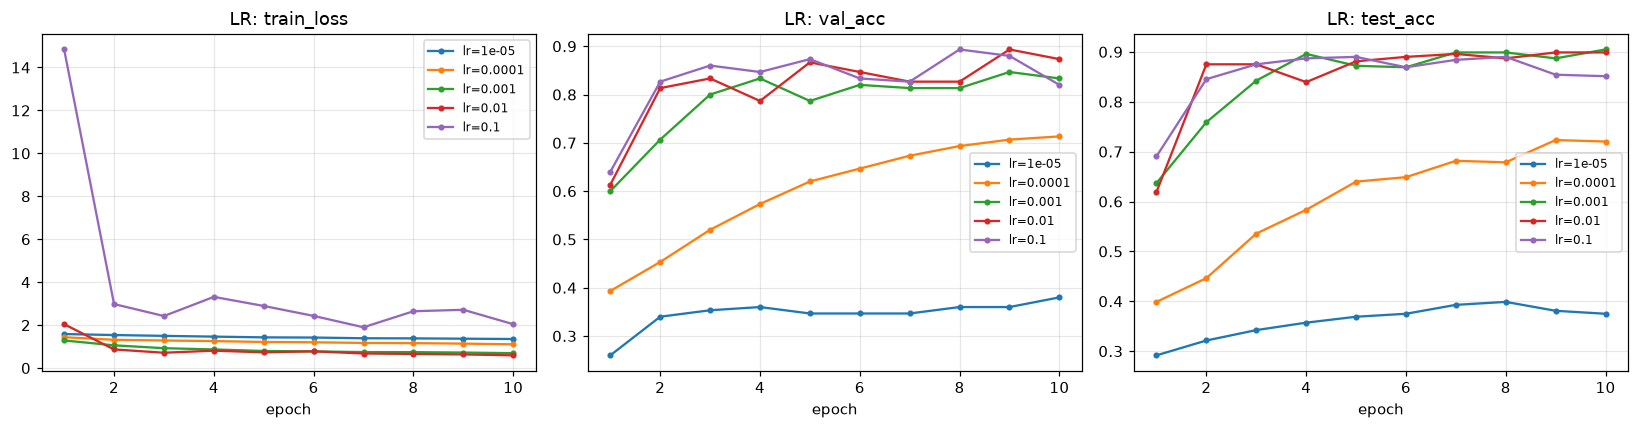

,trainable_params,epochs_run,best_epoch,epochs_to_converge,train_acc(last),val_acc(best),test_acc(last),test_acc@best_val,train-test gap,sec/epoch,total_sec
run,,,,,,,,,,,
lr=1e-05,2052,10,10,10,0.3212,0.3800,0.3750,0.3750,-0.0538,13.1075,131.0747
lr=0.0001,2052,10,10,9,0.5694,0.7133,0.7202,0.7202,-0.1508,13.1101,131.1014
lr=0.001,2052,10,9,9,0.7424,0.8467,0.9048,0.8869,-0.1624,13.1208,131.2079
lr=0.01,2052,10,9,9,0.7741,0.8933,0.8988,0.8988,-0.1247,13.0943,130.9431
lr=0.1,2052,10,8,8,0.7212,0.8933,0.8512,0.8899,-0.1300,13.1583,131.5830


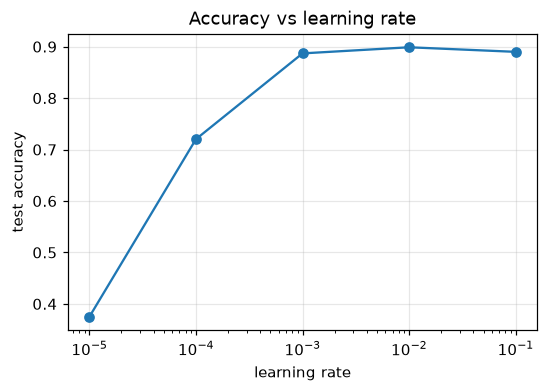

In [25]:
lr_runs = {}
for lr in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]:
    _, h, _ = run(f'lr={lr:g}', lr=lr)
    lr_runs[f'lr={lr:g}'] = h
compare(lr_runs, title='LR:')
tab = summarize(lr_runs); display(tab)

plt.figure(figsize=(5.5, 3.5))
plt.semilogx([float(k.split('=')[1]) for k in lr_runs], tab['test_acc@best_val'], marker='o')
plt.xlabel("learning rate"); plt.ylabel("test accuracy"); plt.title("Accuracy vs learning rate"); plt.show()

Expect: very small LRs converge slowly (underfit within the epoch budget), and very large LRs make the loss bounce and can lower final accuracy.

## 10. Q4: Data augmentation, overfitting, and normalization
Compare no augmentation, flip only, the given augmentations, a heavier set, and the given set with ImageNet normalization (which the pretrained weights expect). Runs are longer (`AUG_EPOCHS`) so we can see when each one overfits. The **train-test accuracy gap** is the overfitting signal. (Train accuracy is measured on augmented batches, so heavy augmentation lowers it by design.)

[aug=none] done in 260s | best epoch 20 | test acc @best-val 0.932
[aug=flip only] done in 260s | best epoch 20 | test acc @best-val 0.932
[aug=given] done in 264s | best epoch 18 | test acc @best-val 0.893
[aug=heavier] done in 278s | best epoch 19 | test acc @best-val 0.917
[aug=given+norm] done in 266s | best epoch 18 | test acc @best-val 0.923


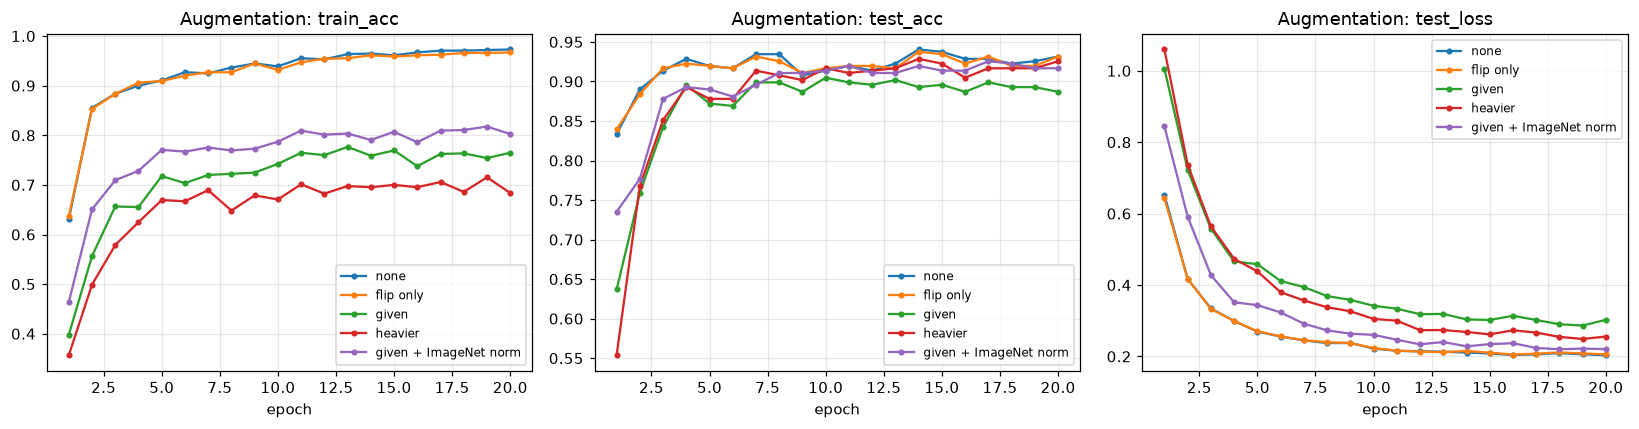

,trainable_params,epochs_run,best_epoch,epochs_to_converge,train_acc(last),val_acc(best),test_acc(last),test_acc@best_val,train-test gap,sec/epoch,total_sec
run,,,,,,,,,,,
none,2052,20,20,6,0.9729,0.9200,0.9315,0.9315,0.0414,12.9808,259.6165
flip only,2052,20,20,6,0.9671,0.9200,0.9315,0.9315,0.0355,13.0151,260.3018
given,2052,20,18,12,0.7647,0.8733,0.8869,0.8929,-0.1222,13.1970,263.9402
heavier,2052,20,19,18,0.6835,0.9000,0.9256,0.9167,-0.2421,13.9208,278.4153
given + ImageNet norm,2052,20,18,8,0.8024,0.9200,0.9167,0.9226,-0.1143,13.2854,265.7085


In [26]:
AUG_EPOCHS = 20
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

aug_sets = {
    'none': transforms.Compose([transforms.Resize((256, 256)), transforms.ToTensor()]),
    'flip only': transforms.Compose([transforms.Resize((256, 256)), transforms.RandomHorizontalFlip(), transforms.ToTensor()]),
    'given': random_transform,
    'heavier': transforms.Compose([
        transforms.RandomResizedCrop(256, scale=(0.3, 1.0)), transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(40), transforms.RandomPerspective(0.3, p=0.5),
        transforms.ColorJitter(0.4, 0.4, 0.4, 0.1), transforms.RandomGrayscale(0.1),
        transforms.GaussianBlur(5), transforms.ToTensor(), transforms.RandomErasing(p=0.5)]),
}
aug_runs = {}
for name, tf in aug_sets.items():
    _, aug_runs[name], _ = run(f'aug={name}', train_tf=tf, epochs=AUG_EPOCHS)

tf_norm = transforms.Compose(random_transform.transforms + [norm])
te_norm = transforms.Compose(common_transform.transforms + [norm])
_, aug_runs['given + ImageNet norm'], _ = run('aug=given+norm', train_tf=tf_norm, test_tf=te_norm, epochs=AUG_EPOCHS)

compare(aug_runs, metrics=('train_acc', 'test_acc', 'test_loss'), title='Augmentation:')
display(summarize(aug_runs))

Overfitting signal: train-test gap per epoch and, when validation loss starts rising.

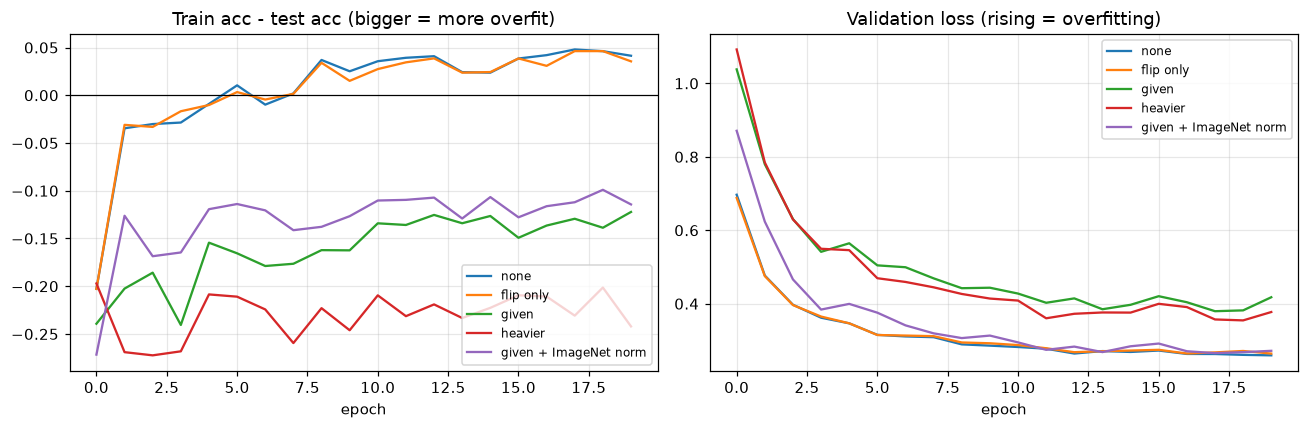

Epoch of minimum validation loss (later = takes longer to overfit):
{'none': 20, 'flip only': 20, 'given': 18, 'heavier': 19, 'given + ImageNet norm': 18}


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in aug_runs.items():
    ax[0].plot(np.array(h['train_acc']) - np.array(h['test_acc']), label=name)
    ax[1].plot(h['val_loss'], label=name)
ax[0].axhline(0, color='k', lw=0.8)
ax[0].set(title="Train acc - test acc (bigger = more overfit)", xlabel="epoch")
ax[1].set(title="Validation loss (rising = overfitting)", xlabel="epoch")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

print("Epoch of minimum validation loss (later = takes longer to overfit):")
print({k: h['best_epoch'] for k, h in aug_runs.items()})

## 11. Q5: Early stopping
`train_model(..., patience=N)` stops when validation loss hasn't improved for N epochs and restores the best weights. With a frozen backbone and linear head, overfitting is mild, so this demo uses **no augmentation and a bigger head** (easier to overfit), 40 max epochs.

[no early stopping] done in 524s | best epoch 7 | test acc @best-val 0.926
[early stopping (patience=5)] done in 160s | best epoch 7 | test acc @best-val 0.926


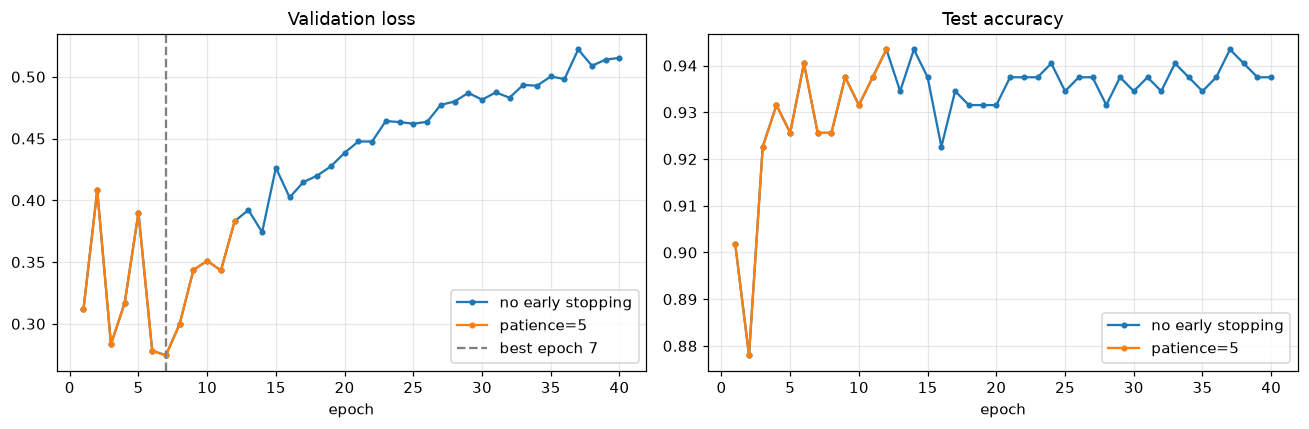

No early stopping : 40 epochs, 524s, final test acc 0.9375
Early stopping    : 12 epochs, 160s, test acc with restored best weights 0.9256


In [28]:
es_kw = dict(train_tf=aug_sets['none'], hidden=512, epochs=40)
m_full, h_full, _ = run('no early stopping', **es_kw)
m_es, h_es, L_es = run('early stopping (patience=5)', patience=5, **es_kw)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for h, lab, c in [(h_full, 'no early stopping', 'C0'), (h_es, 'patience=5', 'C1')]:
    ax[0].plot(range(1, len(h['val_loss']) + 1), h['val_loss'], label=lab, color=c, marker='o', ms=3)
    ax[1].plot(range(1, len(h['test_acc']) + 1), h['test_acc'], label=lab, color=c, marker='o', ms=3)
ax[0].axvline(h_es['best_epoch'], color='gray', ls='--', label=f"best epoch {h_es['best_epoch']}")
ax[0].set(title="Validation loss", xlabel='epoch'); ax[1].set(title="Test accuracy", xlabel='epoch')
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

print(f"No early stopping : {len(h_full['val_loss'])} epochs, {h_full['time']:.0f}s, final test acc {h_full['test_acc'][-1]:.4f}")
print(f"Early stopping    : {len(h_es['val_loss'])} epochs, {h_es['time']:.0f}s, "
      f"test acc with restored best weights {evaluate(m_es, L_es['test'])['acc']:.4f}")

In [29]:
pat_runs = {}
for pat in [2, 5, 10]:
    _, pat_runs[f'patience={pat}'], _ = run(f'patience={pat}', patience=pat, **es_kw)
display(summarize(pat_runs)[['epochs_run', 'best_epoch', 'test_acc@best_val', 'total_sec']])

[patience=2] done in 67s | best epoch 3 | test acc @best-val 0.923
[patience=5] done in 159s | best epoch 7 | test acc @best-val 0.926
[patience=10] done in 223s | best epoch 7 | test acc @best-val 0.926


,epochs_run,best_epoch,test_acc@best_val,total_sec
run,,,,
patience=2,5,3,0.9226,67.1650
patience=5,12,7,0.9256,159.0625
patience=10,17,7,0.9256,222.6952


## 12. Extra: how much training data do we need?
Learning curve: train on 10%, 25%, 50%, 100% of the training split. This shows whether scraping more images is worth it.

[10% data] done in 95s | best epoch 10 | test acc @best-val 0.622
[25% data] done in 101s | best epoch 10 | test acc @best-val 0.824
[50% data] done in 112s | best epoch 10 | test acc @best-val 0.878
[100% data] done in 132s | best epoch 9 | test acc @best-val 0.887


,val_acc(best),test_acc@best_val,best_epoch,total_sec
10%,0.6467,0.6220,10,94.9568
25%,0.7800,0.8244,10,101.1259
50%,0.8533,0.8780,10,112.4548
100%,0.8467,0.8869,9,131.7349


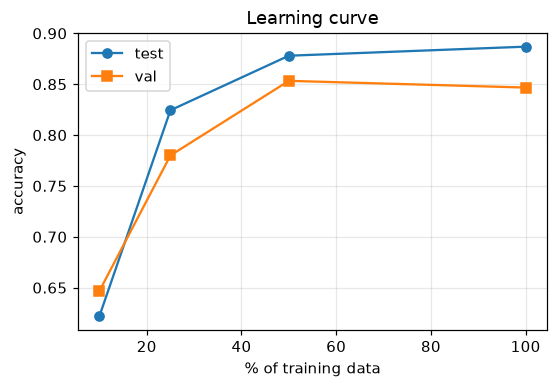

In [30]:
frac_runs = {}
for f in [0.1, 0.25, 0.5, 1.0]:
    _, frac_runs[f], _ = run(f'{int(f*100)}% data', train_frac=f)
fr = summarize(frac_runs)
fr.index = [f"{int(f*100)}%" for f in frac_runs]
display(fr[['val_acc(best)', 'test_acc@best_val', 'best_epoch', 'total_sec']])

plt.figure(figsize=(5.5, 3.5))
plt.plot([f * 100 for f in frac_runs], fr['test_acc@best_val'], marker='o', label='test')
plt.plot([f * 100 for f in frac_runs], fr['val_acc(best)'], marker='s', label='val')
plt.xlabel("% of training data"); plt.ylabel("accuracy"); plt.title("Learning curve"); plt.legend(); plt.show()

Every experiment on one chart (test accuracy @ best validation epoch)

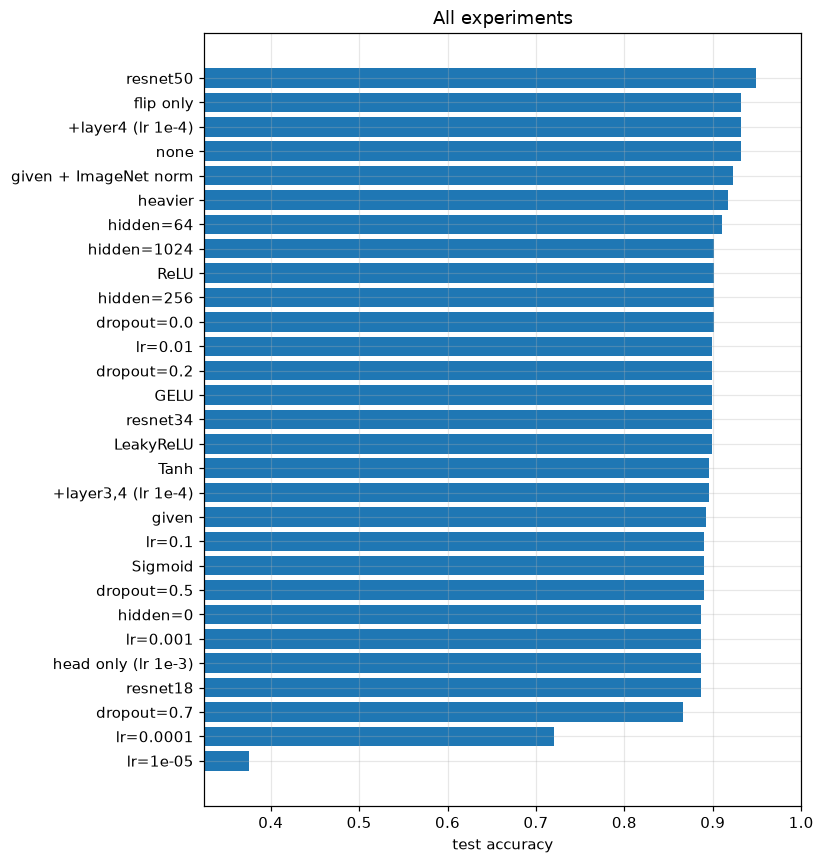

In [31]:
all_runs = {}
for grp in [depth_runs, head_runs, drop_runs, act_runs, ft_runs, lr_runs, aug_runs]:
    all_runs.update(grp)
s = summarize(all_runs)['test_acc@best_val'].sort_values()
plt.figure(figsize=(7, 0.28 * len(s) + 1))
plt.barh(s.index, s.values, color='C0'); plt.xlim(max(0, s.min() - 0.05), 1.0)
plt.xlabel("test accuracy"); plt.title("All experiments"); plt.show()

## 13. Final model

[final] done in 225s | best epoch 11 | test acc @best-val 0.893


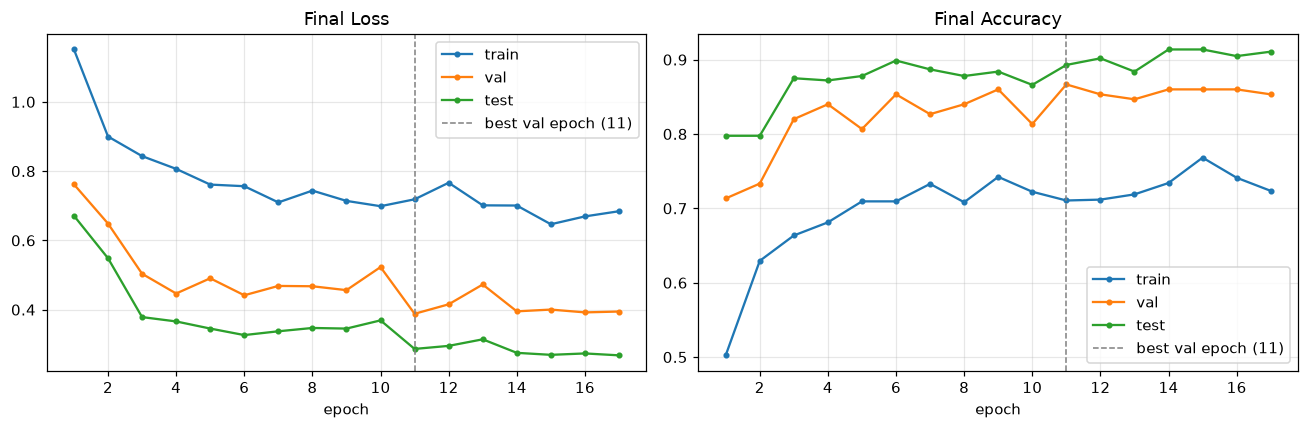

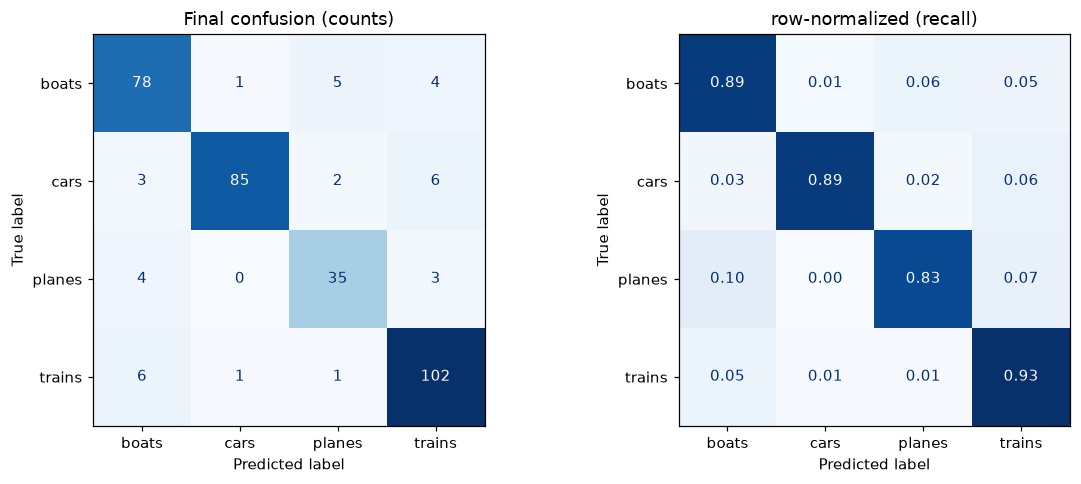

              precision    recall  f1-score   support

       boats      0.857     0.886     0.872        88
        cars      0.977     0.885     0.929        96
      planes      0.814     0.833     0.824        42
      trains      0.887     0.927     0.907       110

    accuracy                          0.893       336
   macro avg      0.884     0.883     0.883       336
weighted avg      0.896     0.893     0.893       336



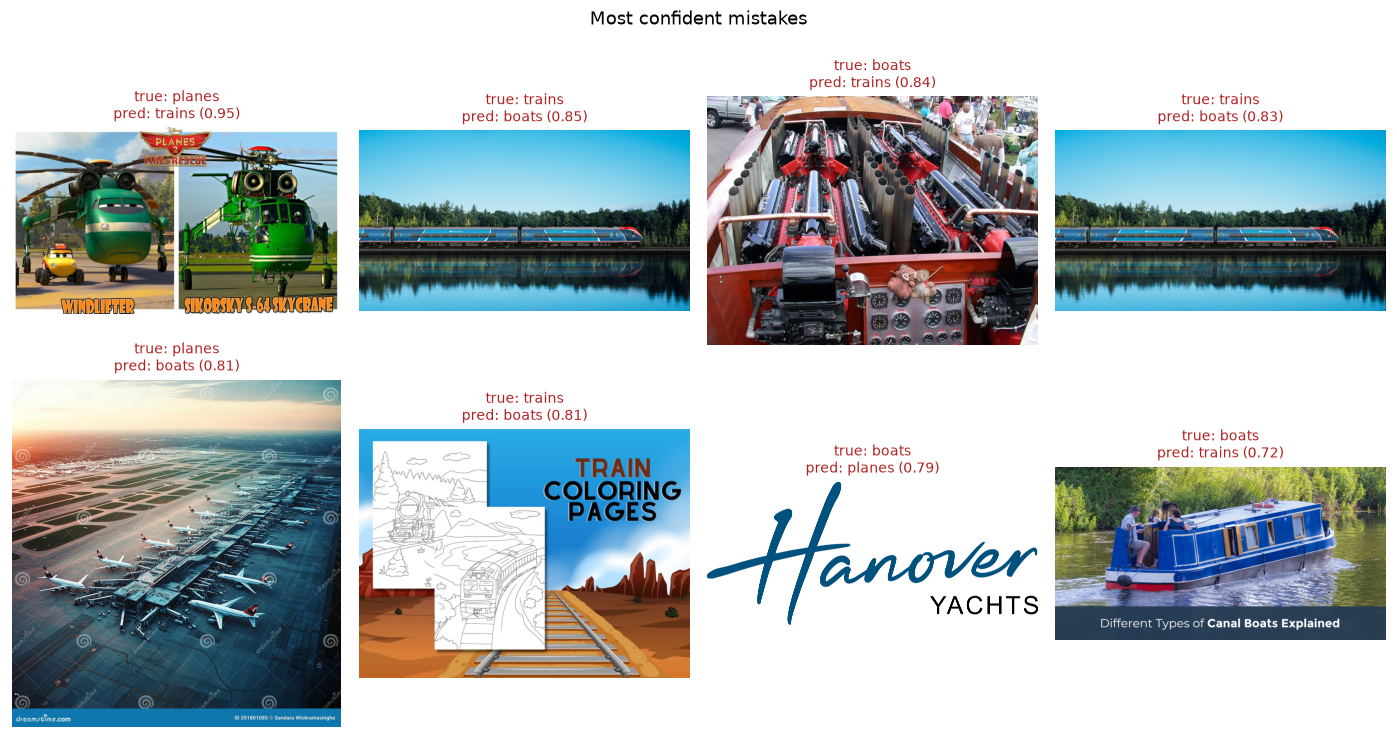

FINAL TEST ACCURACY: 89.29%


In [32]:
BEST = dict(arch='resnet50', hidden=64, dropout=0.0, act=nn.ReLU, unfreeze=(), lr=1e-3,
            train_tf=None, test_tf=None)

final_model, final_h, final_L = run('final', epochs=40, patience=6, **BEST)
plot_history(final_h, 'Final')
r_final = report(final_model, final_L, 'Final')
show_mistakes(r_final, final_L)
print(f"FINAL TEST ACCURACY: {r_final['acc'] * 100:.2f}%")

## Conclusions

**Setup.** Four classes (boats, cars, planes, trains); 850 train / 150 validation / 336 test images. Frozen ResNet18 with a linear head reached 88.7% test accuracy. Planes had the lowest recall (0.76), mostly confused with boats; boats vs planes was also the hardest pairwise problem (90.0%).

**Classes.** Accuracy fell as classes were added (2: 94.6%, 3: 90.7%, 4: 88.7%). Planes is also the smallest class, so its difficulty reflects class size as well as visual similarity.

**Depth.** ResNet18 and 34 were similar (88.7%, 89.9%); ResNet50 reached 94.9% and came within 1% of its best validation accuracy by epoch 3 (vs 9 and 7). Epoch time was identical (~13 s), so data loading, not the network, limits speed.

**Head and fine-tuning.** Width, activation and dropout ≤0.5 made no meaningful difference (all ~87-91%, within test-set noise of about ±3 points); dropout 0.7 hurt (86.6%). Unfreezing layer4 raised accuracy to 93.2%; adding layer3 did not help (89.6%).

**Learning rate.** 1e-5 and 1e-4 underfit within 10 epochs (37.5%, 72.0%); 1e-3 to 1e-1 were all ~89-90%.

**Augmentation.** No augmentation (93.2%) beat the given set (89.3%); heavier augmentation gave 91.7%, and ImageNet normalization improved the given set to 92.3%. Without augmentation, validation loss was still falling at epoch 20, so no overfitting appeared. With a frozen backbone and a 2k-parameter head there is little to overfit, and strong augmentation (vertical flips, 30° rotations, heavy crops) mainly slows learning.

**Early stopping.** Patience 5 stopped at epoch 12 instead of 40 (160 s vs 524 s) with 92.6% vs 93.8% test accuracy; patience 2 took 67 s (92.3%).

**Data.** 10% / 25% / 50% / 100% of the training data gave 62.2% / 82.4% / 87.8% / 88.7%: returns diminish past about half the data.

**Final model.** Combining individually good settings did not guarantee the best model. With 336 test images and one seed, differences under ~3 points should not be over-interpreted.

**Future work.** The full notebook took about 2.5 hours. Next time: (1) resize images to 256 px once, or cache backbone features for head-only experiments, since the GPU waits on JPEG decoding; (2) use early stopping (patience 2-3) instead of fixed epochs, which cut training about 8x here for a ~0.3-point change; (3) drop the pairwise runs, since the confusion matrix gave the same information; (4) run fewer settings per sweep but repeat each over 3 seeds, so conclusions are more statistically defensible rather than single-run.